# 05 — Bayesian Optimization for β-Glucan Nanoparticles

## Objective

Train three Gaussian Process Regression (GPR) models to estimate nanoparticle uptake and macrophage polarization markers, then prioritize untested formulations for the next experimental generation.

The analysis uses numerical formulation descriptors from **02 — Feature Engineering** and candidate formulations from **04 — Generation 1 Formulation Selection**.

**Data status:** The current response measurements are synthetic demonstration data, not experimental observations.

## Analysis workflow

1. Load and align formulation descriptors, Generation 1 selections, and response measurements by formulation `ID`.
2. Validate numerical features and train independent GPR models for log1p-transformed normalized uptake, M1 marker MFI, and M2 marker MFI.
3. Calculate directional expected improvement and select diverse Generation 2 candidates.
4. Visualize predictions, uncertainty, acquisition scores, and measured physical properties.

## Response variables

Three biological responses are modeled on the **natural log1p scale** (`np.log1p(x) = ln(1 + x)`): `log1p_Uptake_norm` (maximize), `log1p_M1_MFI` (maximize), and `log1p_M2_MFI` (minimize). The raw MFI values are retained for traceability. Particle size, PDI, and zeta potential are used for exploratory analysis only.

All example biological responses are synthetic, not experimental measurements.

In [1]:
from pathlib import Path
from itertools import product
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from scipy.stats import norm

SEED=42
N_NEXT=10
XI=0.01
DIVERSITY_WEIGHT=0.25
# Weights sum to 1; use directional standardized improvements so M2 is minimized.
WEIGHTS={'log1p_Uptake_norm':0.4,'log1p_M1_MFI':0.3,'log1p_M2_MFI':0.3}
DIRECTIONS={'log1p_Uptake_norm':1,'log1p_M1_MFI':1,'log1p_M2_MFI':1}
DATA_NAME = 'generation_01_measurements_DEMO.csv'
DATA_PATH = next((p for p in [
    Path('../data/demo') / DATA_NAME,
    Path('data/demo') / DATA_NAME,
    Path(DATA_NAME),
    Path('../') / DATA_NAME,
    Path('/mnt/data') / DATA_NAME,
] if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f'Missing {DATA_NAME}. Current working directory: {Path.cwd()}')
measured = pd.read_csv(DATA_PATH)
assert measured.ID.is_unique and len(measured) == 20
assert measured.Data_Type.str.startswith('SYNTHETIC').all() and measured.Data_Type.str.endswith('NOT_EXPERIMENTAL').all()

# Compute all MFI-related log1p columns; keep raw measurements unchanged.
RAW_TO_LOG = {
    'Cell Uptake (MFI)': 'log1p_Cell_Uptake_MFI',
    'Uptake_norm': 'log1p_Uptake_norm',
    'M1 Marker (MFI)': 'log1p_M1_MFI',
    'M2 Marker (MFI)': 'log1p_M2_MFI',
}
for raw_col, log_col in RAW_TO_LOG.items():
    if raw_col not in measured:
        if log_col not in measured:
            raise KeyError(f'Missing both {raw_col} and {log_col}')
        continue
    vals = pd.to_numeric(measured[raw_col], errors='raise')
    if vals.isna().any() or (vals < 0).any():
        raise ValueError(f'{raw_col} must contain nonnegative finite measurements')
    measured[log_col] = np.log1p(vals)
print('MFI targets are transformed with natural log1p (ln(1 + MFI)).')
print('Synthetic training rows:',len(measured))
display(measured[['ID','Particle Size (nm)','PDI','Zeta Potential (mV)','log1p_Cell_Uptake_MFI',*WEIGHTS]].head())

MFI targets are transformed with natural log1p (ln(1 + MFI)).
Synthetic training rows: 20


,ID,Particle Size (nm),PDI,Zeta Potential (mV),log1p_Cell_Uptake_MFI,log1p_Uptake_norm,log1p_M1_MFI,log1p_M2_MFI
0,YG-SA-D1-N1-R90-10-MU-G08,104.73,0.135,-28.30,8.963693,2.564949,7.245705,8.533342
1,YG-SA-D2-N2-R90-10-MU-G08,202.15,0.097,-46.40,9.307277,8.366603,8.941065,7.027137
2,YG-SA-D3-N3-R90-10-MU-G08,132.60,0.128,-14.93,7.978750,7.955425,8.250377,7.969565
3,YG-SA-D4-N4-R90-10-MU-G08,231.70,0.336,-30.20,9.169701,3.437208,7.334773,8.464046
4,YG-SA-D5-N5-R90-10-MU-G08,299.25,0.416,-8.72,8.167534,8.202756,8.487146,7.760765


## 1. Load and validate formulation features

Read the numerical feature matrix exported by **02 — Feature Engineering** and the formulation IDs exported by **04 — Generation 1 Formulation Selection**. Match records by `ID` and check completeness, uniqueness, and numeric validity before fitting the models.

In [2]:
# Load feature matrix and candidate universe.
# Use the numerical descriptors exported by feature engineering.
def find_file(paths):
    return next((p for p in paths if p.is_file()), None)

FEATURE_REPRESENTATION = 'chemical_full'  # alternative: 'property_based'
FEATURE_NAME = {
    'chemical_full': 'formulation_features_chemical_full.csv',
    'property_based': 'formulation_features_property_based.csv',
}[FEATURE_REPRESENTATION]
FEATURE_PATH = find_file([
    Path('../data/processed') / FEATURE_NAME,
    Path('data/processed') / FEATURE_NAME,
    Path(FEATURE_NAME),
    Path('/mnt/data') / FEATURE_NAME,
    Path('/mnt/data/data/processed') / FEATURE_NAME,
])
if FEATURE_PATH is None:
    raise FileNotFoundError(
        f'Notebook 02 export {FEATURE_NAME} is missing. Run Notebook 02 on Dataset.xlsx '
        'and place its data/processed CSV in the project. This model intentionally has no fallback features.'
    )
feature_table = pd.read_csv(FEATURE_PATH)
if 'ID' not in feature_table or feature_table.ID.isna().any() or feature_table.ID.duplicated().any():
    raise ValueError('Notebook 02 features must have a non-null unique ID column')

# Notebook 04 exports candidate_snapshot.csv under results/generation_01_seed_*/.
snapshots = list(Path('../results').glob('generation_01_seed_*/candidate_snapshot.csv')) + list(Path('results').glob('generation_01_seed_*/candidate_snapshot.csv'))
SNAPSHOT_PATH = find_file([Path('candidate_snapshot.csv'), Path('/mnt/data/candidate_snapshot.csv'), *sorted(snapshots, key=lambda p:p.stat().st_mtime, reverse=True)])
if SNAPSHOT_PATH is None:
    raise FileNotFoundError('Notebook 04 candidate_snapshot.csv not found. Run Notebook 04 before Notebook 05.')
candidates = pd.read_csv(SNAPSHOT_PATH)
if 'ID' not in candidates or candidates.ID.isna().any() or candidates.ID.duplicated().any():
    raise ValueError('Notebook 04 candidate snapshot must have unique non-null IDs')

selection_files = list(Path('../results').glob('generation_01_seed_*/generation_01_selection.csv')) + list(Path('results').glob('generation_01_seed_*/generation_01_selection.csv'))
SELECTION_PATH = find_file([SNAPSHOT_PATH.parent/'generation_01_selection.csv', Path('generation_01_selection.csv'), Path('/mnt/data/generation_01_selection.csv'), *selection_files])
if SELECTION_PATH is None:
    raise FileNotFoundError('Notebook 04 generation_01_selection.csv not found')
selection = pd.read_csv(SELECTION_PATH)
if 'ID' not in selection or selection.ID.duplicated().any():
    raise ValueError('Notebook 04 selection must have unique IDs')
if set(measured.ID) != set(selection.ID):
    raise ValueError('DEMO measurement IDs do not exactly match Notebook 04 selection IDs')
if not set(candidates.ID).issubset(set(feature_table.ID)):
    missing = sorted(set(candidates.ID)-set(feature_table.ID))
    raise ValueError(f'Notebook 02 feature export lacks {len(missing)} candidate IDs; first examples: {missing[:5]}')
if not set(measured.ID).issubset(set(candidates.ID)):
    raise ValueError('Measurements contain IDs outside Notebook 04 candidate snapshot')

features = candidates[['ID']].merge(feature_table,on='ID',how='left',validate='one_to_one')
cols = [c for c in features if c != 'ID']
features[cols] = features[cols].apply(pd.to_numeric,errors='raise')
if not np.isfinite(features[cols].to_numpy(dtype=float)).all():
    raise ValueError('Notebook 02 features contain non-finite values')
training = measured.merge(features,on='ID',validate='one_to_one')
pool = features.loc[~features.ID.isin(measured.ID)].reset_index(drop=True)
# Notebook 02 has already standardized descriptors; the GP-specific scaler is fitted
# only to observed Generation 1 training rows, for all observed formulations.
scaler = StandardScaler().fit(training[cols])
X = scaler.transform(training[cols]); XP = scaler.transform(pool[cols])
feature_source = str(FEATURE_PATH)
candidate_source = str(SNAPSHOT_PATH)
selection_source = str(SELECTION_PATH)
print('Feature representation:', FEATURE_REPRESENTATION)
print('Notebook 02 feature source:', feature_source)
print('Notebook 04 snapshot:', candidate_source)
print('Notebook 04 selection:', selection_source)
print('Train:',len(training),'Pool:',len(pool),'Features:',len(cols))


Feature representation: chemical_full
Notebook 02 feature source: ..\data\processed\formulation_features_chemical_full.csv
Notebook 04 snapshot: ..\results\generation_01_seed_42\candidate_snapshot.csv
Notebook 04 selection: ..\results\generation_01_seed_42\generation_01_selection.csv
Train: 20 Pool: 6460 Features: 86


## 2. Gaussian Process surrogate models

Fit an independent Gaussian Process Regression model for each log1p-transformed biological response using all observed Generation 1 formulations. Predict response means and uncertainties for untested candidates.

In [3]:
def make_gp():
    kernel = (
        ConstantKernel(1.0, (1e-2, 1e2))
        * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e3), nu=2.5)
        + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-4, 1e1))
    )
    return GaussianProcessRegressor(
        kernel=kernel, alpha=1e-6, random_state=SEED, n_restarts_optimizer=10
    )

models = {}
scalers = {}
prediction = {}
model_summary = []

for target in WEIGHTS:
    y_scaler = StandardScaler().fit(training[[target]])
    y = y_scaler.transform(training[[target]]).ravel()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        gp = make_gp().fit(X, y)
    mu, sd = gp.predict(XP, return_std=True)
    prediction[target] = {
        'mu': y_scaler.inverse_transform(mu.reshape(-1, 1)).ravel(),
        'sd': sd * y_scaler.scale_[0],
        'mu_scaled': mu,
        'sd_scaled': sd,
        'best_scaled': max(DIRECTIONS[target] * y),
    }
    models[target] = gp
    scalers[target] = y_scaler
    model_summary.append({'Target': target, 'Fitted_Kernel': str(gp.kernel_)})

model_summary_df = pd.DataFrame(model_summary)
display(model_summary_df)


,Target,Fitted_Kernel
0,log1p_Uptake_norm,"1.02**2 * Matern(length_scale=5.62, nu=2.5) + ..."
1,log1p_M1_MFI,"1.11**2 * Matern(length_scale=5.37, nu=2.5) + ..."
2,log1p_M2_MFI,"1.03**2 * Matern(length_scale=4.13, nu=2.5) + ..."


## 3. Multi-target acquisition and candidate selection

Calculate expected improvement for each objective, accounting for the direction of optimization. Combine standardized acquisition values with target weights and select a batch of untested formulations while encouraging diversity.

In [4]:
def ei_max(mu,sd,best,xi=XI):
    gain=mu-best-xi
    z=np.divide(gain,sd,out=np.zeros_like(gain),where=sd>0)
    return np.where(sd>0,np.maximum(gain*norm.cdf(z)+sd*norm.pdf(z),0),0)
results=pool[['ID']].copy()
for target in WEIGHTS:
    p=prediction[target]
    results[f'{target} predicted']=p['mu']
    results[f'{target} SD']=p['sd']
    results[f'{target} EI']=ei_max(DIRECTIONS[target]*p['mu_scaled'],p['sd_scaled'],p['best_scaled'])
results['Weighted_EI']=sum(WEIGHTS[t]*results[f'{t} EI'] for t in WEIGHTS)
results=results.sort_values(['Weighted_EI','ID'],ascending=[False,True]).reset_index(drop=True)
# Batch diversity selection
xp=scaler.transform(features.set_index('ID').loc[results.ID,cols]);remaining=list(range(len(results)));chosen=[]
scale=max(float(np.median(np.linalg.norm(xp-xp.mean(axis=0),axis=1))),1e-9)
for _ in range(min(N_NEXT,len(results))):
    if not chosen: idx=remaining[int(np.argmax(results.Weighted_EI.to_numpy()[remaining]))]
    else:
        dist=np.linalg.norm(xp[remaining,None,:]-xp[None,chosen,:],axis=2).min(axis=1)
        bonus=DIVERSITY_WEIGHT*max(results.Weighted_EI.max(),1e-12)*(1-np.exp(-dist/scale))
        idx=remaining[int(np.argmax(results.Weighted_EI.to_numpy()[remaining]+bonus))]
    chosen.append(idx);remaining.remove(idx)
suggestions=results.iloc[chosen].copy();suggestions.insert(0,'BO_Rank',range(1,len(suggestions)+1))
assert not suggestions.ID.isin(measured.ID).any()
display(suggestions[['BO_Rank','ID','log1p_Uptake_norm predicted','log1p_M1_MFI predicted','log1p_M2_MFI predicted','Weighted_EI']])

,BO_Rank,ID,log1p_Uptake_norm predicted,log1p_M1_MFI predicted,log1p_M2_MFI predicted,Weighted_EI
0,1,YG-SA-D2-N2-R70-30-MH-G20,8.232302,8.768046,7.452127,0.120271
3,2,YG-SA-D2-N2-R50-50-MH-G08,8.142588,8.681722,7.566713,0.116967
1,3,YG-SA-D2-N2-R70-30-MH-G08,8.325823,8.771837,7.422727,0.118673
2,4,YG-SA-D2-N2-R50-50-MH-G20,8.080665,8.684208,7.583376,0.118436
5,5,YG-SA-D2-N2-R50-50-MM-G20,8.143154,8.671349,7.603260,0.111887
12,6,YG-SA-D3-N2-R50-50-MM-G20,8.543811,8.519358,7.799617,0.103727
4,7,YG-SA-D2-N2-R70-30-MH-G01,8.274033,8.737602,7.452983,0.113582
7,8,YG-SA-D2-N2-R90-10-MH-G20,8.183711,8.784963,7.395410,0.109552
6,9,YG-SA-D2-N2-R50-50-MH-G01,8.088526,8.651751,7.589102,0.111674
8,10,YG-SA-D2-N2-R70-30-MM-G20,8.259565,8.746191,7.472958,0.109209


## 4. Predicted responses and uncertainty

Visualize predicted log1p-scale mean responses and uncertainty intervals for the selected Generation 2 formulations.

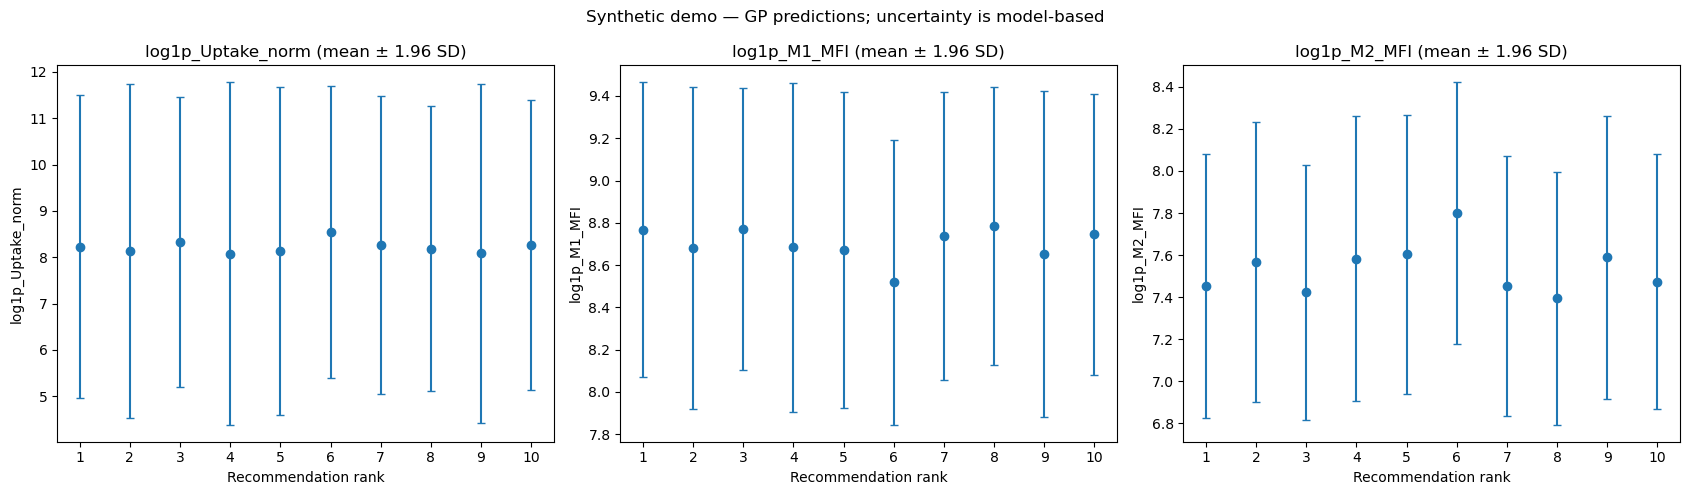

In [5]:
fig,axes=plt.subplots(1,3,figsize=(17,5))
for ax,target in zip(axes,WEIGHTS):
    x=np.arange(len(suggestions));means=suggestions[f'{target} predicted'].to_numpy();sd=suggestions[f'{target} SD'].to_numpy()
    ax.errorbar(x,means,yerr=1.96*sd,fmt='o',capsize=3)
    ax.set_xticks(x,[str(i) for i in suggestions.BO_Rank]);ax.set_xlabel('Recommendation rank')
    ax.set_ylabel(target);ax.set_title(target+' (mean ± 1.96 SD)')
fig.suptitle('Synthetic demo — GP predictions; uncertainty is model-based');plt.tight_layout();plt.show()

## 5. Acquisition score contributions

Inspect the contribution of each target to the combined acquisition score.

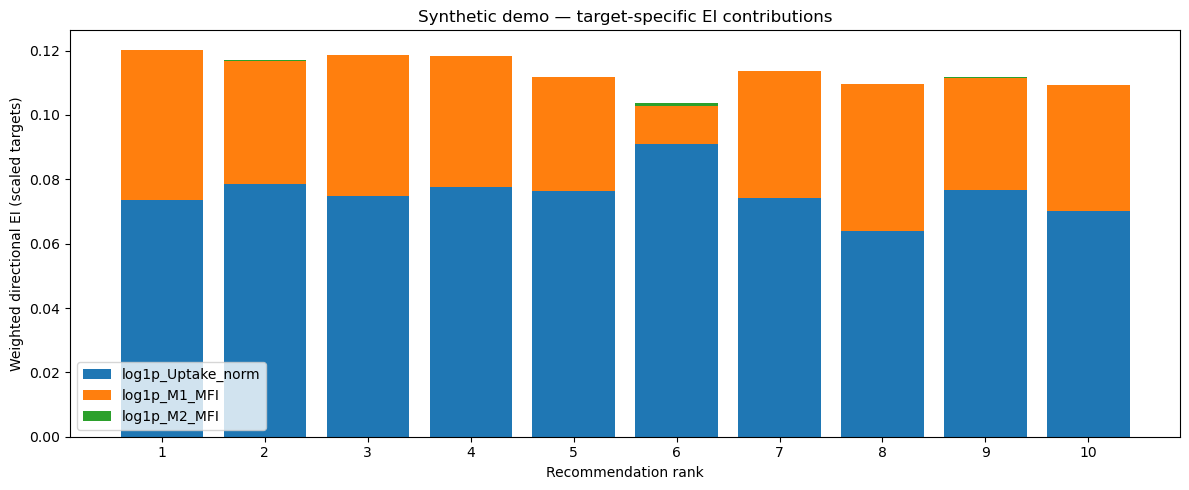

,BO_Rank,ID,log1p_Uptake_norm EI,log1p_M1_MFI EI,log1p_M2_MFI EI
0,1,YG-SA-D2-N2-R70-30-MH-G20,0.183600,0.156027,0.000078
3,2,YG-SA-D2-N2-R50-50-MH-G08,0.196113,0.127819,0.000585
1,3,YG-SA-D2-N2-R70-30-MH-G08,0.186710,0.146598,0.000032
2,4,YG-SA-D2-N2-R50-50-MH-G20,0.193754,0.135638,0.000811
5,5,YG-SA-D2-N2-R50-50-MM-G20,0.190813,0.117765,0.000775
12,6,YG-SA-D3-N2-R50-50-MM-G20,0.227562,0.039464,0.002875
4,7,YG-SA-D2-N2-R70-30-MH-G01,0.185390,0.131359,0.000062
7,8,YG-SA-D2-N2-R90-10-MH-G20,0.160132,0.151645,0.000020
6,9,YG-SA-D2-N2-R50-50-MH-G01,0.191946,0.115522,0.000795
8,10,YG-SA-D2-N2-R70-30-MM-G20,0.175653,0.129762,0.000062


In [11]:
fig,ax=plt.subplots(figsize=(12,5));xx=np.arange(len(suggestions));bottom=np.zeros(len(suggestions))
for target in WEIGHTS:
    v=(WEIGHTS[target]*suggestions[f'{target} EI']).to_numpy()
    ax.bar(xx,v,bottom=bottom,label=target);bottom+=v
ax.set_xticks(xx,[str(i) for i in suggestions.BO_Rank]);ax.set_xlabel('Recommendation rank')
ax.set_ylabel('Weighted directional EI (scaled targets)');ax.legend();ax.set_title('Synthetic demo — target-specific EI contributions');plt.tight_layout();plt.show()
ei_cols = [f'{target} EI' for target in WEIGHTS]

display(
    suggestions[
        ['BO_Rank', 'ID'] + ei_cols
    ].round(6)
)

## 6. Predicted M1–M2 trade-off

Compare the predicted polarization-marker responses across candidate formulations. Larger bubbles represent higher predicted log1p-normalized uptake. This visualization does not alter the acquisition score or selected formulations.

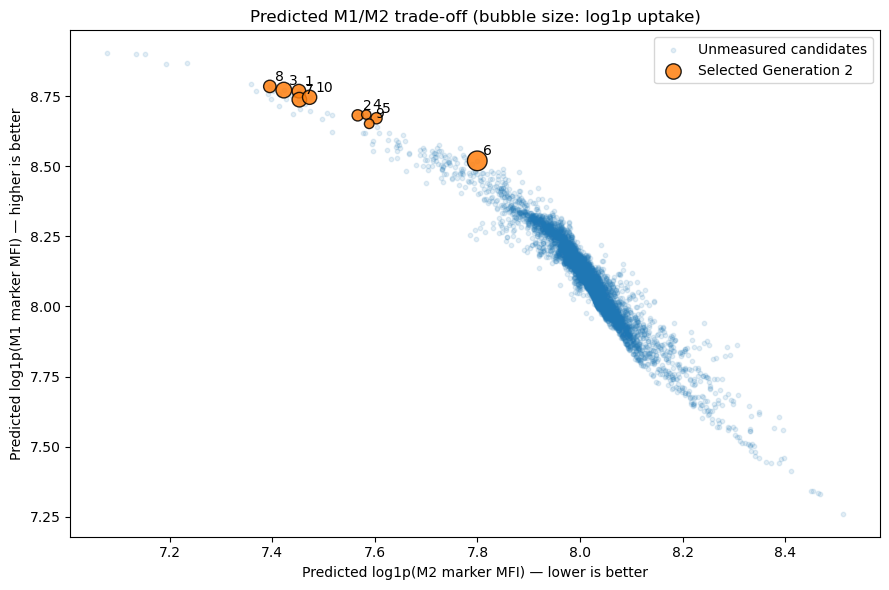

In [7]:
# Predicted M1/M2 trade-off; bubble size indicates predicted log1p uptake.
m1_col = 'log1p_M1_MFI predicted'
m2_col = 'log1p_M2_MFI predicted'
uptake_col = 'log1p_Uptake_norm predicted'

required = [m1_col, m2_col, uptake_col]
for name, frame in [('results', results), ('suggestions', suggestions)]:
    missing = [col for col in required if col not in frame.columns]
    if missing:
        raise KeyError(f'{name} missing prediction columns: {missing}')

uptake = suggestions[uptake_col].to_numpy(dtype=float)
span = np.ptp(uptake)
bubble_sizes = 45 + 155 * (uptake - uptake.min()) / (span if span > 0 else 1.0)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    results[m2_col], results[m1_col],
    s=10, alpha=0.12, label='Unmeasured candidates'
)
ax.scatter(
    suggestions[m2_col], suggestions[m1_col],
    s=bubble_sizes, alpha=0.85, edgecolors='black',
    label='Selected Generation 2'
)
for _, row in suggestions.iterrows():
    ax.annotate(
        str(int(row['BO_Rank'])),
        (row[m2_col], row[m1_col]),
        xytext=(4, 4), textcoords='offset points'
    )
ax.set_xlabel('Predicted log1p(M2 marker MFI) — lower is better')
ax.set_ylabel('Predicted log1p(M1 marker MFI) — higher is better')
ax.set_title('Predicted M1/M2 trade-off (bubble size: log1p uptake)')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Physical properties and biological responses

Explore the relationships between measured size, PDI, zeta potential, and biological responses. These properties are not assumed to be available for untested candidates.

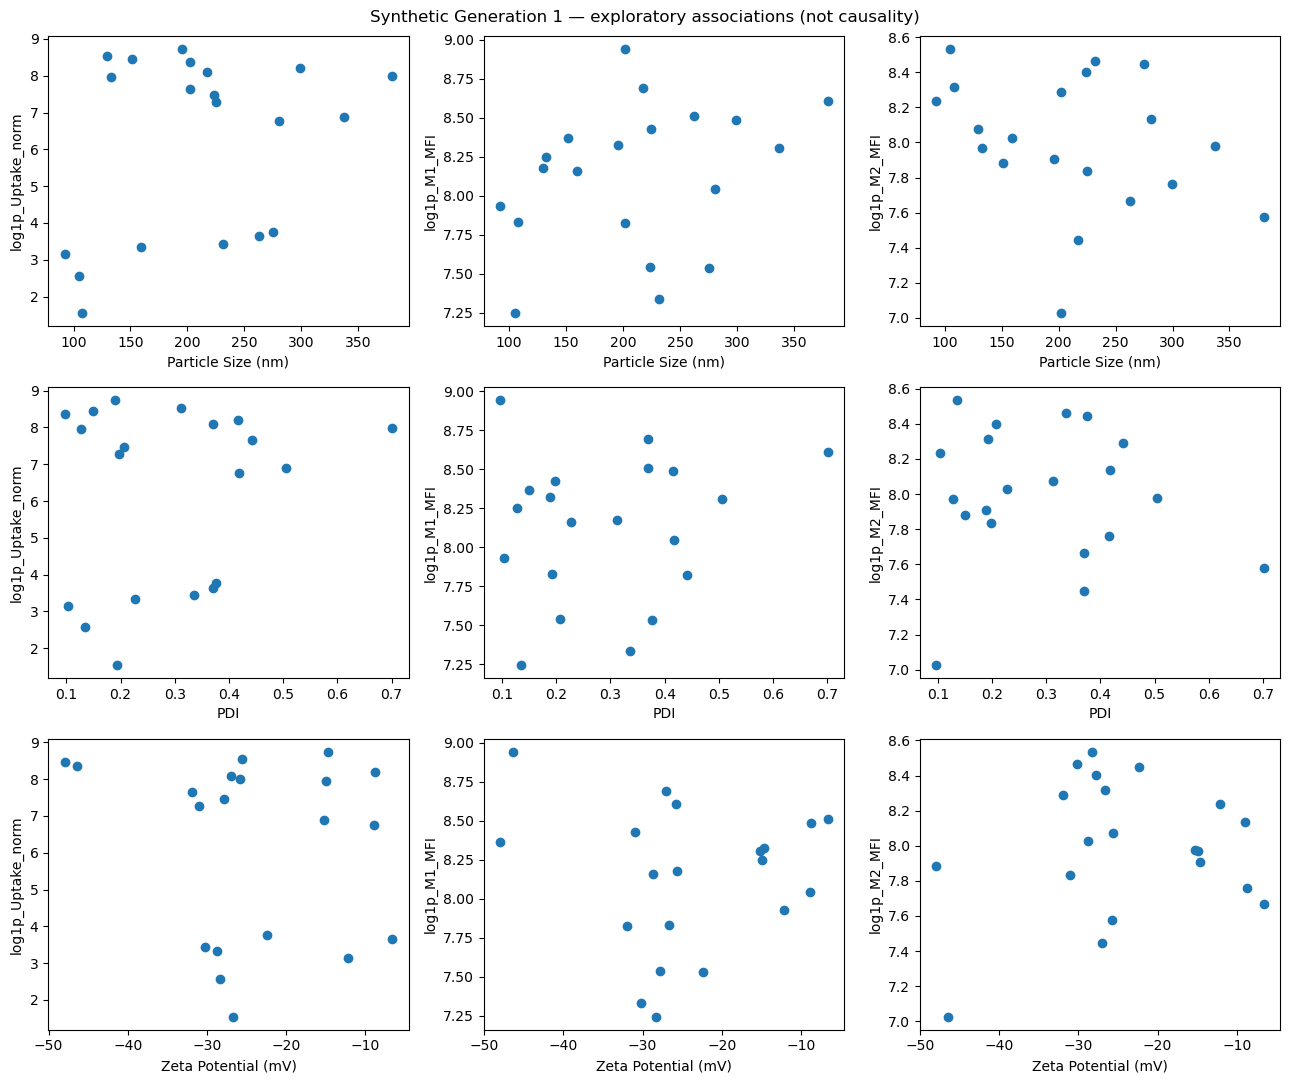

In [8]:
phys=['Particle Size (nm)','PDI','Zeta Potential (mV)'];targets=list(WEIGHTS)
fig,axes=plt.subplots(3,3,figsize=(13,11))
for i,p in enumerate(phys):
    for j,t in enumerate(targets):
        ax=axes[i,j];ax.scatter(measured[p],measured[t]);ax.set_xlabel(p);ax.set_ylabel(t)
fig.suptitle('Synthetic Generation 1 — exploratory associations (not causality)');plt.tight_layout();plt.show()

In [9]:
for target, gp in models.items():
    print(f"\n{target}")
    print("Fitted kernel:", gp.kernel_)
    print("Log marginal likelihood:", gp.log_marginal_likelihood_value_)


log1p_Uptake_norm
Fitted kernel: 1.02**2 * Matern(length_scale=5.62, nu=2.5) + WhiteKernel(noise_level=0.0001)
Log marginal likelihood: -25.99423928197813

log1p_M1_MFI
Fitted kernel: 1.11**2 * Matern(length_scale=5.37, nu=2.5) + WhiteKernel(noise_level=0.0001)
Log marginal likelihood: -27.991137140579237

log1p_M2_MFI
Fitted kernel: 1.03**2 * Matern(length_scale=4.13, nu=2.5) + WhiteKernel(noise_level=0.0001)
Log marginal likelihood: -27.870736293604615


## 8. Export Bayesian Optimization outputs

Save candidate predictions, Generation 2 recommendations, fitted surrogate model information, and data provenance to `results/bayesian_optimization/`.

In [10]:
# Save outputs under the project results directory.
RESULTS_ROOT = Path('../results') if Path('../data').is_dir() else Path('results')
OUT = RESULTS_ROOT / 'bayesian_optimization'
OUT.mkdir(parents=True, exist_ok=True)
results.to_csv(OUT/'all_candidate_predictions_DEMO.csv',index=False,encoding='utf-8-sig')
suggestions.to_csv(OUT/'generation_02_multi_target_recommendations_DEMO.csv',index=False,encoding='utf-8-sig')
model_summary_df.to_csv(OUT/'surrogate_models_DEMO.csv',index=False,encoding='utf-8-sig')
import json
(OUT/'data_provenance_DEMO.json').write_text(json.dumps({
    'data':str(DATA_PATH),'candidate_source':candidate_source,
    'generation_1_selection':selection_source,'feature_source':feature_source,
    'n_training':len(training),'n_candidates':len(pool),'n_features':len(cols),
    'targets':list(WEIGHTS),'target_transform':'natural_log1p','synthetic':True
},indent=2,ensure_ascii=False),encoding='utf-8')
print('Saved to',OUT.resolve())
print('DEMO only: all outcomes synthetic; no biological validation.')


Saved to C:\Users\洪家賢\NAS\AI code\Nanoparticle-AI-Optimization\results\bayesian_optimization
DEMO only: all outcomes synthetic; no biological validation.


## Interpretation and limitations

- All modeled MFI responses use the natural log1p scale. The biological responses are synthetic and cannot support experimental conclusions.
- A small Generation 1 training set and a high-dimensional feature space may limit predictive performance.
- Marker MFI is not equivalent to the percentage of M1 or M2 macrophages; biological interpretation requires appropriate controls and gating.
- Candidate recommendations should be validated experimentally and revisited as new measurements become available.